# 02 — Baseline model

Builds and solves the MILP of [`docs/formulation.md`](../docs/formulation.md) with Gurobi. Each constraint is added in its own function block, preceded by its equation. The solution is then validated independently of the model and summarised with KPIs computed from the roster $x$.

Notebook 03 reuses the functions defined here (`%run 02_baseline_model.ipynb`).

**All results are obtained with synthetic data** (notebook 01) and do not describe any real hospital.

## 1. Setup

In [1]:
import json
from collections import defaultdict
from pathlib import Path

import gurobipy as gp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gurobipy import GRB

DATA_DIR = Path("..") / "data" / "synthetic"
FIG_DIR = Path("..") / "results" / "figures"
TAB_DIR = Path("..") / "results" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load instance

Mapping between the files of an instance and the symbols of the formulation:

| File | Symbols |
|---|---|
| `calendar.csv` | $\mathcal{D}$, $\mathcal{F}$ (`is_F`), $\mathcal{L}$, $PL_d$ (`PL`) |
| `residents.csv` | $\mathcal{R}$, $\mathcal{R}_S$ (`senior`), $\mathcal{R}_1$ (`first_year`), $G^{\min}_r$, $G^{\max}_r$, $H_r$, $\Phi_r$ (`Phi`) |
| `demand.csv` | $\mathcal{G}$, $N_{dg}$, $S_{dg}$, $U_{dg}$ |
| `eligibility.csv` | $E_{rdg}$ |
| `availability.csv` | $ROT_{rd}$ |
| `requests.csv` | $\mathcal{P}$, $Q_{rd}$ |
| `previous_month.csv` | $Y_{rd}$, $d \in \{-1, 0\}$ |

In [2]:
FILES = ["calendar", "residents", "demand", "eligibility", "availability", "requests", "previous_month"]


def load_instance(name, root=DATA_DIR):
    path = root / name
    inst = {key: pd.read_csv(path / f"{key}.csv") for key in FILES}
    inst["meta"] = json.loads((path / "meta.json").read_text())
    inst["name"] = name
    return inst


def drop_residents(inst, residents):
    # Copy of the instance without the given residents (workforce sensitivity).
    out = dict(inst)
    for key in ["residents", "eligibility", "availability", "requests", "previous_month"]:
        out[key] = inst[key][~inst[key]["resident"].isin(residents)].reset_index(drop=True)
    out["name"] = f"{inst['name']}_minus{len(residents)}"
    return out


def index_instance(inst):
    # Sets and parameters as Python dictionaries, named after the formulation.
    cal = inst["calendar"].set_index("day")
    res = inst["residents"].set_index("resident")
    dem = inst["demand"].set_index(["day", "duty"])
    E = inst["eligibility"]
    s = {
        "R": list(res.index),
        "R_S": list(res.index[res["senior"]]),
        "R_1": list(res.index[res["first_year"]]),
        "D": list(cal.index),
        "G": sorted(inst["demand"]["duty"].unique()),
        "F": list(cal.index[cal["is_F"]]),
        "L": list(cal.index[~cal["is_F"]]),
        "N": dem["N"].to_dict(), "S": dem["S"].to_dict(), "U": dem["U"].to_dict(),
        "E_keys": [tuple(k) for k in E.loc[E["E"] == 1, ["resident", "day", "duty"]].itertuples(index=False)],
        "G_min": res["G_min"].to_dict(), "G_max": res["G_max"].to_dict(),
        "H": res["H"].to_dict(), "Phi": res["Phi"].to_dict(),
        "ROT": inst["availability"].set_index(["resident", "day"])["ROT"].to_dict(),
        "PL": cal["PL"].to_dict(),
        "Q": inst["requests"].set_index(["resident", "day"])["Q"].to_dict(),
        "Y_prev": {(r, d): 1 for r, d in inst["previous_month"][["resident", "day"]].itertuples(index=False)},
    }
    s["n"] = len(s["D"])
    eligible_F = {r for r, d, g in s["E_keys"] if d in set(s["F"])}
    s["R_F"] = [r for r in s["R"] if s["Phi"][r] > 0 and r in eligible_F]
    return s

## 3. Model

`build_model(inst, scenario)` creates the variables, the constraints (1)–(9) and the lexicographic objective.

**Scenario B in this checkpoint.** Constraint (10) needs the redesigned scenario-B duty types and durations $T_g$, which are not yet in the data. If every duty is a 17-hour module ($T_g = 17$), constraint (10) is equivalent to $\sum_d y_{rd} \le 4 + C_r$; scenario B therefore uses $G^{\max}_r = \min(G^{\max}_r, 4 + C_r)$ with $C_r = 0$, and the scenario-B version of constraint (9). This is a preliminary approximation.

In [3]:
def build_model(inst, scenario="A", objective="lex", weights=(1000, 100, 10, 1), verbose=False):
    s = index_instance(inst)
    R, D, G, F, L, n = s["R"], s["D"], s["G"], s["F"], s["L"], s["n"]
    G_max = dict(s["G_max"])
    if scenario == "B":
        G_max = {r: min(G_max[r], 4) for r in R}  # constraint (10) with T_g = 17 and C_r = 0

    m = gp.Model(f"roster_{inst['name']}_{scenario}")
    m.Params.OutputFlag = int(verbose)

    # ---- Decision variables -------------------------------------------------------
    x = m.addVars(s["E_keys"], vtype=GRB.BINARY, name="x")            # x_rdg, only where E_rdg = 1 (3a)
    h = m.addVars(D, G, name="h")                                       # h_dg   uncovered positions
    hS = m.addVars([(d, g) for d in D for g in G if s["S"][d, g] > 0], name="hS")  # h^S_dg
    hP = m.addVars(L, name="hP")                                        # h^P_d
    hG = m.addVars(R, name="hG")                                        # h^G_r
    v = m.addVars(R, range(-1, n - 1), name="v")                        # v_rd, d = -1..n-2
    e_max = m.addVar(name="e_max")
    e_min = m.addVar(name="e_min")

    duties_of = defaultdict(list)
    for r, d, g in s["E_keys"]:
        duties_of[r, d].append(g)

    def y(r, d):
        # y_rd = sum_g x_rdg for d in D; Y_rd (data) for d in {-1, 0}; 0 outside the horizon.
        if d <= 0:
            return s["Y_prev"].get((r, d), 0)
        if d > n:
            return 0
        return gp.quicksum(x[r, d, g] for g in duties_of[r, d])

    def has_vars(expr):
        return isinstance(expr, gp.LinExpr) and expr.size() > 0

    # ---- (1) Coverage ---------------------------------------------------------------
    for d in D:
        for g in G:
            m.addConstr(x.sum("*", d, g) + h[d, g] == s["N"][d, g], name=f"c1_cover[{d},{g}]")

    # ---- (2a) Senior presence, (2b) first-year limit ---------------------------------
    for (d, g) in hS:
        m.addConstr(gp.quicksum(x[r, d, g] for r in s["R_S"] if (r, d, g) in x) + hS[d, g] >= s["S"][d, g],
                    name=f"c2a_senior[{d},{g}]")
    for d in D:
        for g in G:
            junior = [x[r, d, g] for r in s["R_1"] if (r, d, g) in x]
            if junior:
                m.addConstr(gp.quicksum(junior) <= s["U"][d, g], name=f"c2b_first_year[{d},{g}]")

    # ---- (3b) At most one duty per day ------------------------------------------------
    for (r, d), gs in duties_of.items():
        if len(gs) > 1:
            m.addConstr(y(r, d) <= 1, name=f"c3b_one_per_day[{r},{d}]")

    # ---- (4) Rest after a duty: d = 0..n-1 -------------------------------------------
    for r in R:
        for d in range(0, n):
            expr = gp.LinExpr(y(r, d)) + y(r, d + 1)
            if has_vars(expr):
                m.addConstr(expr <= 1, name=f"c4_rest[{r},{d}]")

    # ---- (5) Alternate-day pattern (soft): d = -1..n-2 --------------------------------
    for r in R:
        for d in range(-1, n - 1):
            expr = gp.LinExpr(y(r, d)) + y(r, d + 2)
            if has_vars(expr):
                m.addConstr(expr <= 1 + v[r, d], name=f"c5_alternate[{r},{d}]")

    # ---- (6a) Monthly minimum, (6b) monthly maximum -------------------------------------
    for r in R:
        total = gp.quicksum(y(r, d) for d in D)
        m.addConstr(total + hG[r] >= s["G_min"][r], name=f"c6a_min[{r}]")
        m.addConstr(total <= G_max[r], name=f"c6b_max[{r}]")

    # ---- (7) Requested days off: no constraint, penalised in f2 -------------------------

    # ---- (8) Fairness of weekends and public holidays -----------------------------------
    for r in s["R_F"]:
        load = (s["H"][r] + gp.quicksum(y(r, d) for d in F)) * (1.0 / s["Phi"][r])
        m.addConstr(load <= e_max, name=f"c8_max[{r}]")
        m.addConstr(load >= e_min, name=f"c8_min[{r}]")

    # ---- (9) Residents available for ordinary activity ----------------------------------
    for d in L:
        present = gp.quicksum(
            s["ROT"].get((r, d), 0) * (1 - gp.LinExpr(y(r, d - 1)) - (y(r, d) if scenario == "B" else 0))
            for r in R)
        m.addConstr(present + hP[d] >= s["PL"][d], name=f"c9_ordinary[{d}]")

    # ---- Objective ----------------------------------------------------------------------
    f1 = h.sum() + hS.sum() + hP.sum() + hG.sum()
    f2 = gp.quicksum(q * y(r, d) for (r, d), q in s["Q"].items())
    f3 = e_max - e_min
    f4 = v.sum()
    m.ModelSense = GRB.MINIMIZE
    if objective == "lex":
        for i, (f, name) in enumerate([(f1, "f1_unmet"), (f2, "f2_requests"), (f3, "f3_fairness"), (f4, "f4_patterns")]):
            m.setObjectiveN(f, index=i, priority=4 - i, name=name)
    else:
        m.setObjective(weights[0] * f1 + weights[1] * f2 + weights[2] * f3 + weights[3] * f4)

    m._vars = {"x": x, "h": h, "hS": hS, "hP": hP, "hG": hG, "v": v, "e_max": e_max, "e_min": e_min}
    m._sets, m._scenario = s, scenario
    return m

## 4. Solve and status handling

Every level of the lexicographic objective is solved to proven optimality (`MIPGap = 0`) within a time limit. Since the model is always feasible (formulation, Section 6), an infeasible status can only mean a data error.

In [4]:
def solve(m, time_limit=120):
    m.Params.MIPGap = 0
    m.Params.TimeLimit = time_limit
    m.optimize()
    if m.Status == GRB.INFEASIBLE:
        raise RuntimeError("Infeasible model: this indicates a data error (see formulation, Section 6).")
    if m.SolCount == 0:
        raise RuntimeError(f"No solution found (status {m.Status}).")
    if m.Status != GRB.OPTIMAL:
        print(f"Warning: status {m.Status}, best solution returned.")
    x = m._vars["x"]
    return pd.DataFrame([k for k in x if x[k].X > 0.5], columns=["resident", "day", "duty"])

## 5. Solution validation and KPIs

`validate` checks the hard constraints directly on the roster, without using the Gurobi model. `kpis` computes every indicator from the roster (formulation, Section 7), so the reported figures do not depend on slack-variable values.

In [5]:
def y_table(roster, s):
    y = {(r, d): 0 for r in s["R"] for d in s["D"]}
    for r, d in roster[["resident", "day"]].itertuples(index=False):
        y[r, d] += 1
    for (r, d), val in s["Y_prev"].items():
        y[r, d] = val
    return y


def validate(roster, inst, scenario="A"):
    s = index_instance(inst)
    y = y_table(roster, s)
    get = lambda r, d: y.get((r, d), 0)
    cnt = roster.groupby(["day", "duty"]).size()
    first = roster[roster["resident"].isin(s["R_1"])].groupby(["day", "duty"]).size()
    g_max = {r: (min(s["G_max"][r], 4) if scenario == "B" else s["G_max"][r]) for r in s["R"]}
    checks = {
        "(3a) assignment without eligibility": int((~roster.apply(tuple, axis=1).isin(set(s["E_keys"]))).sum()),
        "(3b) more than one duty per day": sum(get(r, d) > 1 for r in s["R"] for d in s["D"]),
        "(4) duties on consecutive days": sum(get(r, d) + get(r, d + 1) > 1 for r in s["R"] for d in range(0, s["n"])),
        "(1) more residents than required": int((cnt > pd.Series(s["N"]).reindex(cnt.index)).sum()),
        "(2b) too many first-year residents": int((first > pd.Series(s["U"]).reindex(first.index)).sum()),
        "(6b) above monthly maximum": sum(sum(get(r, d) for d in s["D"]) > g_max[r] for r in s["R"]),
    }
    return pd.Series(checks, name="violations")


def kpis(roster, inst, scenario="A"):
    s = index_instance(inst)
    y = y_table(roster, s)
    get = lambda r, d: y.get((r, d), 0)
    cnt = roster.groupby(["day", "duty"]).size()
    sen = roster[roster["resident"].isin(s["R_S"])].groupby(["day", "duty"]).size()
    uncovered = sum(max(0, s["N"][k] - cnt.get(k, 0)) for k in s["N"])
    senior_short = sum(max(0, s["S"][k] - sen.get(k, 0)) for k in s["S"])
    present = {d: sum(s["ROT"].get((r, d), 0) * (1 - get(r, d - 1) - (get(r, d) if scenario == "B" else 0))
                      for r in s["R"]) for d in s["L"]}
    ordinary_short = sum(max(0, s["PL"][d] - present[d]) for d in s["L"])
    duties = {r: sum(get(r, d) for d in s["D"]) for r in s["R"]}
    gmin_short = sum(max(0, s["G_min"][r] - duties[r]) for r in s["R"])
    violated = [(r, d) for (r, d) in s["Q"] if get(r, d) == 1]
    load_before = {r: s["H"][r] / s["Phi"][r] for r in s["R_F"]}
    load_after = {r: (s["H"][r] + sum(get(r, d) for d in s["F"])) / s["Phi"][r] for r in s["R_F"]}
    patterns = sum(get(r, d) + get(r, d + 2) == 2 for r in s["R"] for d in range(-1, s["n"] - 1))
    active = [duties[r] for r in s["R"] if s["G_max"][r] > 0]
    return pd.Series({
        "uncovered duty positions": uncovered,
        "missing seniors": senior_short,
        "missing residents for ordinary activity": ordinary_short,
        "duties below training minimum": gmin_short,
        "f1 unmet requirements": uncovered + senior_short + ordinary_short + gmin_short,
        "requests violated / total": f"{len(violated)} / {len(s['Q'])}",
        "f2 weighted violated requests": sum(s["Q"][k] for k in violated),
        "weekend/holiday load range before the month": round(max(load_before.values()) - min(load_before.values()), 2),
        "f3 weekend/holiday load range after the month": round(max(load_after.values()) - min(load_after.values()), 2),
        "f4 alternate-day patterns": patterns,
        "duties per resident (min-max)": f"{min(active)}-{max(active)}",
        "min residents for ordinary activity on a working day": min(present.values()),
    }, name=f"{inst['name']} ({scenario})")

## 6. Baseline: January 2027, scenario A

In [6]:
base = load_instance("jan2027_base")
model = build_model(base, scenario="A")
roster = solve(model)
print(f"{model.NumVars} variables ({model.NumIntVars} binary), {model.NumConstrs} constraints, "
      f"runtime {model.Runtime:.1f} s")
for i in range(model.NumObj):
    model.Params.ObjNumber = i
    print(f"{model.ObjNName}: {model.ObjNVal:g}")
validate(roster, base)

Set parameter Username
Set parameter LicenseID to value 2860142
Academic license - for non-commercial use only - expires 2027-09-03
1352 variables (758 binary), 1393 constraints, runtime 0.3 s
f1_unmet: 1.0001e-06
f2_requests: 0
f3_fairness: 14.7784
f4_patterns: 1


(3a) assignment without eligibility    0
(3b) more than one duty per day        0
(4) duties on consecutive days         0
(1) more residents than required       0
(2b) too many first-year residents     0
(6b) above monthly maximum             0
Name: violations, dtype: int64

In [7]:
baseline_kpis = kpis(roster, base)
baseline_kpis

uncovered duty positions                                     0
missing seniors                                              0
missing residents for ordinary activity                      0
duties below training minimum                                0
f1 unmet requirements                                        0
requests violated / total                               0 / 17
f2 weighted violated requests                                0
weekend/holiday load range before the month              21.71
f3 weekend/holiday load range after the month            14.78
f4 alternate-day patterns                                    1
duties per resident (min-max)                              5-7
min residents for ordinary activity on a working day         9
Name: jan2027_base (A), dtype: object

### Roster

Each cell shows the duty assigned to a resident on a day. Grey: unavailable (vacation, external rotation, course). Red frame: requested day off. Shaded columns: weekends and public holidays.

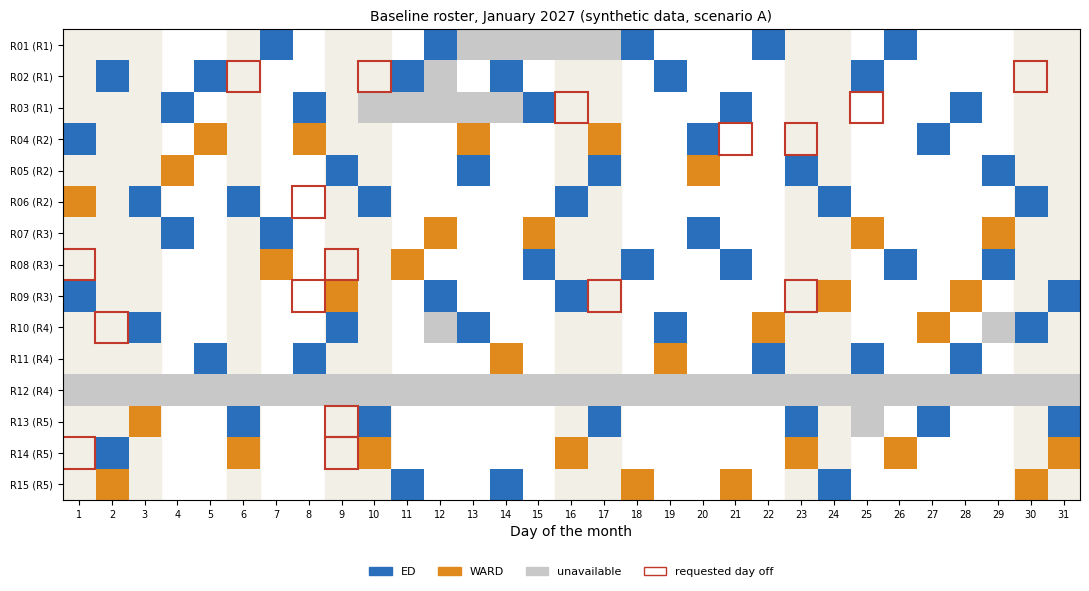

In [8]:
def plot_roster(roster, inst, title, path=None):
    s = index_instance(inst)
    R, D = s["R"], s["D"]
    codes = {g: i + 1 for i, g in enumerate(s["G"])}
    grid = np.zeros((len(R), len(D)))
    avail = inst["availability"].set_index(["resident", "day"])["available"]
    for i, r in enumerate(R):
        for j, d in enumerate(D):
            if avail.get((r, d), 1) == 0:
                grid[i, j] = -1
    for r, d, g in roster.itertuples(index=False):
        grid[R.index(r), D.index(d)] = codes[g]
    cmap = plt.matplotlib.colors.ListedColormap(["#c8c8c8", "#ffffff", "#2a6fbb", "#e08a1e"])
    fig, ax = plt.subplots(figsize=(11, 0.32 * len(R) + 1.2))
    for j, d in enumerate(D):
        if d in s["F"]:
            ax.axvspan(j - 0.5, j + 0.5, color="#f2efe6", zorder=0)
    ax.imshow(np.ma.masked_where(grid == 0, grid), cmap=cmap, vmin=-1, vmax=2, aspect="auto", zorder=1)
    for (r, d) in s["Q"]:
        ax.add_patch(plt.Rectangle((D.index(d) - 0.5, R.index(r) - 0.5), 1, 1, fill=False, ec="#c0392b", lw=1.5, zorder=2))
    ax.set_xticks(range(len(D)), D, fontsize=7)
    ax.set_yticks(range(len(R)), [f"{r} (R{y})" for r, y in zip(R, inst["residents"]["year"])], fontsize=7)
    ax.set_xlabel("Day of the month")
    handles = [plt.matplotlib.patches.Patch(color=c, label=l) for c, l in
               [("#2a6fbb", s["G"][0]), ("#e08a1e", s["G"][1]), ("#c8c8c8", "unavailable")]]
    handles.append(plt.matplotlib.patches.Patch(fill=False, ec="#c0392b", label="requested day off"))
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=8, frameon=False)
    ax.set_title(title, fontsize=10)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    return fig


plot_roster(roster, base, "Baseline roster, January 2027 (synthetic data, scenario A)",
            FIG_DIR / "roster_jan2027_base.png");

### Fairness of weekend and holiday duties

Normalised load $(H_r + \sum_{d \in \mathcal{F}} y_{rd}) / \Phi_r$ before and after the month. The model gives more weekend/holiday duties to the residents who carried fewer in previous months.

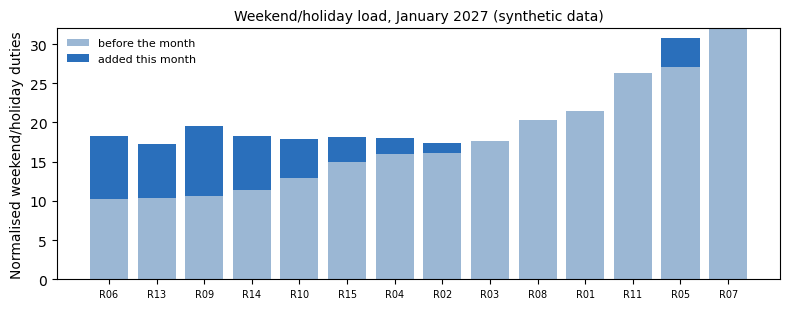

In [9]:
def plot_fairness(roster, inst, title, path=None):
    s = index_instance(inst)
    y = y_table(roster, s)
    R_F = s["R_F"]
    before = np.array([s["H"][r] / s["Phi"][r] for r in R_F])
    after = np.array([(s["H"][r] + sum(y.get((r, d), 0) for d in s["F"])) / s["Phi"][r] for r in R_F])
    order = np.argsort(before)
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.bar(np.arange(len(R_F)), before[order], color="#9bb7d4", label="before the month")
    ax.bar(np.arange(len(R_F)), (after - before)[order], bottom=before[order], color="#2a6fbb", label="added this month")
    ax.set_xticks(range(len(R_F)), [R_F[i] for i in order], fontsize=7)
    ax.set_ylabel("Normalised weekend/holiday duties")
    ax.legend(fontsize=8, frameon=False)
    ax.set_title(title, fontsize=10)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    return fig


plot_fairness(roster, base, "Weekend/holiday load, January 2027 (synthetic data)", FIG_DIR / "fairness_jan2027_base.png");

## 7. Preliminary stress tests

Three quick experiments to see where the model starts reporting unmet requirements. They anticipate the sensitivity analysis of notebook 03.

1. **Demanding month:** December 2026 (Christmas holidays and more vacations).
2. **Smaller workforce:** January 2027 removing up to four residents.
3. **Scenario B (approximation):** January 2027 with at most four 17-hour duties per resident and residents on duty not counted for ordinary activity.

In [10]:
results = [baseline_kpis]

dec = load_instance("dec2026_christmas")
dec_roster = solve(build_model(dec, "A"))
assert validate(dec_roster, dec).sum() == 0
results.append(kpis(dec_roster, dec))

removal_order = ["R15", "R08", "R05", "R14"]  # one R5, one R3, one R2, another R5
for k in range(1, len(removal_order) + 1):
    reduced = drop_residents(base, removal_order[:k])
    r_roster = solve(build_model(reduced, "A"))
    assert validate(r_roster, reduced).sum() == 0
    results.append(kpis(r_roster, reduced))

b_roster = solve(build_model(base, "B"))
assert validate(b_roster, base, "B").sum() == 0
results.append(kpis(b_roster, base, "B"))

summary = pd.concat(results, axis=1)
summary.to_csv(TAB_DIR / "checkpoint_summary.csv")
summary

,jan2027_base (A),dec2026_christmas (A),jan2027_base_minus1 (A),jan2027_base_minus2 (A),jan2027_base_minus3 (A),jan2027_base_minus4 (A),jan2027_base (B)
uncovered duty positions,0,5,2,9,20,32,37
missing seniors,0,0,0,0,0,0,0
missing residents for ordinary activity,0,1,0,0,5,12,0
duties below training minimum,0,0,0,0,0,0,0
f1 unmet requirements,0,6,2,9,25,44,37
requests violated / total,0 / 17,0 / 12,0 / 17,0 / 15,0 / 15,0 / 13,0 / 17
f2 weighted violated requests,0,0,0,0,0,0,0
weekend/holiday load range before the month,21.71,27.54,21.71,21.71,21.71,21.71,21.71
f3 weekend/holiday load range after the month,14.78,23.08,14.78,14.78,14.78,14.78,17.14
f4 alternate-day patterns,1,0,1,1,1,1,0


## 8. Observations for the checkpoint

The interpretation of these results is written in the checkpoint report (`docs/checkpoint/`). The figures and the summary table are saved in `results/`.